In [6]:
import torch, torch.nn as nn, torch.nn.functional as F
import numpy as np, librosa, matplotlib.pyplot as plt
from datasets import load_dataset

device = "cuda" if torch.cuda.is_available() else "cpu"

class NADE(nn.Module):
    """Model binary feature vectors autoregressively."""

    def __init__(self, D: int, H: int):
        super().__init__()
        self.D = D
        self.H = H
        self.W = nn.Parameter(torch.randn(D, H) * 0.01)
        self.V = nn.Parameter(torch.randn(D, H) * 0.01)
        self.b = nn.Parameter(torch.zeros(D))
        self.c = nn.Parameter(torch.zeros(H))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        memory = self.c.expand(x.size(0), -1)
        logits = []
        for i in range(self.D):
            h = torch.sigmoid(memory)
            logits.append(self.b[i] + (h * self.V[i]).sum(dim=1))
            memory = memory + x[:, i].unsqueeze(1) * self.W[i]
        return torch.stack(logits, dim=1)

    @torch.no_grad()
    def sample(self, num_samples: int) -> torch.Tensor:
        memory = self.c.expand(num_samples, -1).clone()
        samples = torch.zeros(
            num_samples, self.D, device=self.W.device, dtype=self.W.dtype
        )
        for i in range(self.D):
            h = torch.sigmoid(memory)
            probability = torch.sigmoid(self.b[i] + (h * self.V[i]).sum(dim=1))
            samples[:, i] = torch.bernoulli(probability)
            memory = memory + samples[:, i].unsqueeze(1) * self.W[i]
        return samples

    def compute_surprise(self, x: torch.Tensor) -> torch.Tensor:
        logits = self.forward(x)
        return F.binary_cross_entropy_with_logits(logits, x)

def surprise(model, X, bs=256):  # average surprise per pixel, per example
    model.eval(); res = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            xb = X[i:i+bs].to(device)
            res.append(F.binary_cross_entropy_with_logits(model(xb), xb, reduction="none").mean(1).cpu())
    return torch.cat(res)

def train(model, X, epochs, bs=64, lr=1e-3):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    curve = []
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(X)); tot = 0
        for i in range(0, len(X), bs):
            xb = X[perm[i:i+bs]].to(device)
            loss = model.compute_surprise(xb)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(xb)
        curve.append(tot / len(X)); print(ep+1, round(curve[-1], 4))
    return curve

DatasetDict({
    train: Dataset({
        features: ['audio', 'label'],
        num_rows: 2700
    })
    test: Dataset({
        features: ['audio', 'label'],
        num_rows: 300
    })
})
torch.Size([2700, 512]) torch.Size([300, 512])


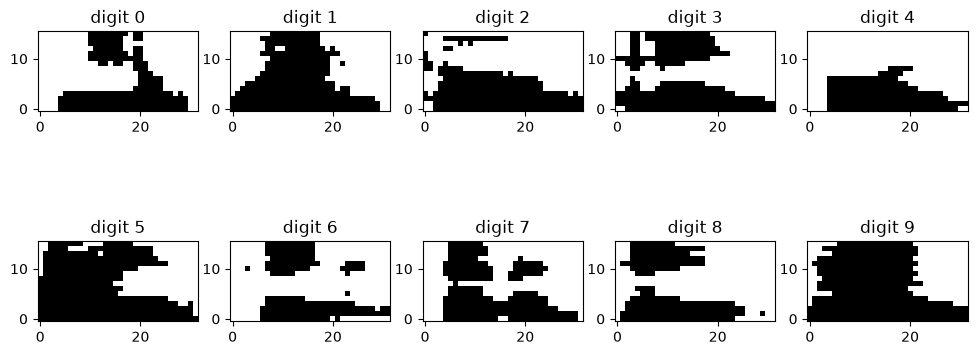

In [8]:
import soundfile as sf, io
from datasets import Audio

# decode audio with soundfile (no torchcodec/FFmpeg needed on Windows)
ds = load_dataset("mteb/free-spoken-digit-dataset").cast_column("audio", Audio(decode=False))
print(ds)   # check the split names and column names (usually 'audio' and 'label')

def to_bits(example):
    y, sr = sf.read(io.BytesIO(example["audio"]["bytes"]), dtype="float32")
    y, _ = librosa.effects.trim(y, top_db=20)                 # cut silence
    mel = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=16, n_fft=256, hop_length=32)
    mel = F.adaptive_avg_pool1d(torch.tensor(mel)[None], 32)[0].numpy()   # exactly 32 time steps -> (16, 32)
    db = librosa.power_to_db(mel, ref=np.max)                 # 0 dB = loudest moment
    bits = (db > -30).astype(np.float32).T                    # (32 time, 16 pitch)
    return bits.reshape(-1)                                   # 512, time-major

def convert(split):
    X = np.stack([to_bits(e) for e in ds[split]])
    return torch.tensor(X), torch.tensor(ds[split]["label"])

Xtr, ytr = convert("train"); Xte, yte = convert("test")
print(Xtr.shape, Xte.shape)    # (2700, 512) (300, 512)

# one picture per digit
fig, ax = plt.subplots(2, 5, figsize=(12, 5))
for d in range(10):
    img = Xtr[ytr == d][0].reshape(32, 16).T       # pitch up, time right
    ax[d//5, d%5].imshow(img, origin="lower", cmap="gray_r"); ax[d//5, d%5].set_title(f"digit {d}")
plt.show()

1 0.5594
2 0.4702
3 0.4608
4 0.4561
5 0.4507
6 0.4418
7 0.4305
8 0.4189
9 0.4064
10 0.3931
11 0.38
12 0.3674
13 0.3559
14 0.345
15 0.3353
16 0.3264
17 0.3185
18 0.3117
19 0.3054
20 0.3
21 0.295
22 0.2906
23 0.2864
24 0.2826
25 0.2789
26 0.2755
27 0.2723
28 0.2693
29 0.2663
30 0.2635


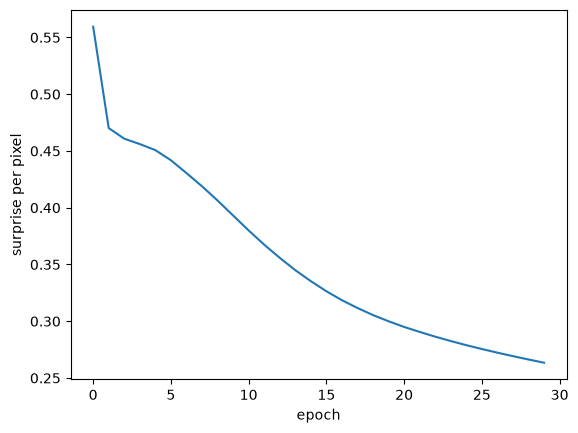

In [9]:
speech_nade = NADE(512, 50).to(device)
curve = train(speech_nade, Xtr, epochs=30)
plt.plot(curve); plt.xlabel("epoch"); plt.ylabel("surprise per pixel"); plt.show()

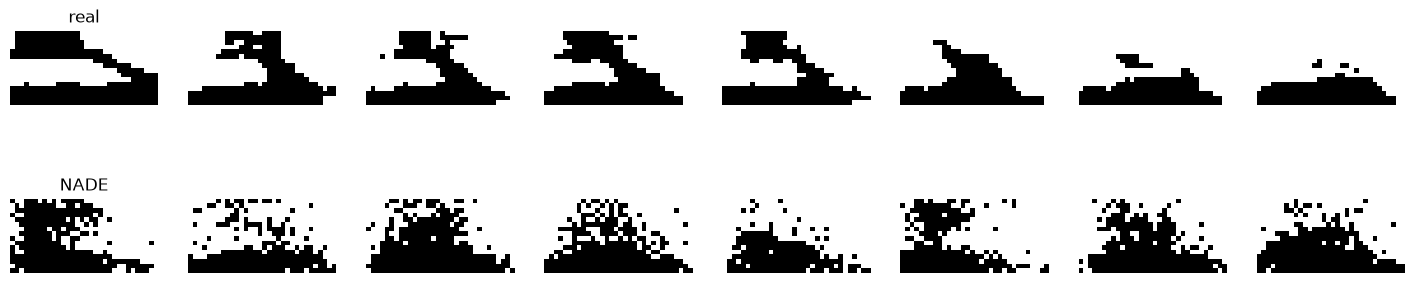

In [10]:
samples = speech_nade.sample(8).cpu()
fig, ax = plt.subplots(2, 8, figsize=(18, 4))
for i in range(8):
    ax[0, i].imshow(Xte[i].reshape(32, 16).T, origin="lower", cmap="gray_r"); ax[0, i].axis("off")
    ax[1, i].imshow(samples[i].reshape(32, 16).T, origin="lower", cmap="gray_r"); ax[1, i].axis("off")
ax[0, 0].set_title("real"); ax[1, 0].set_title("NADE")
plt.show()

{'real': 0.26456117630004883, 'backwards': 0.41136032342910767, 'upside-down': 0.6764011979103088}


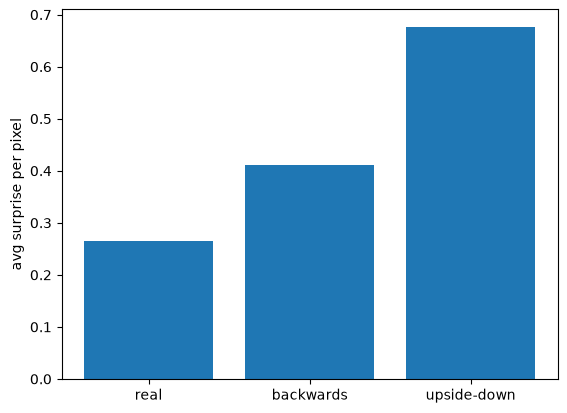

In [11]:
Xr = Xte.reshape(-1, 32, 16)
back = Xr.flip(1).reshape(-1, 512)    # flip time
upside = Xr.flip(2).reshape(-1, 512)  # flip pitch

scores = {"real": surprise(speech_nade, Xte).mean().item(),
          "backwards": surprise(speech_nade, back).mean().item(),
          "upside-down": surprise(speech_nade, upside).mean().item()}
print(scores)
plt.bar(scores.keys(), scores.values()); plt.ylabel("avg surprise per pixel"); plt.show()

In [ ]:
# Report the measured ranking from this run (not assumed)
ranked = sorted(scores.items(), key=lambda kv: kv[1])
print(" < ".join(f"{name} ({val:.3f})" for name, val in ranked))
print("Most surprising:", ranked[-1][0])
print("Expected order holds:", [n for n, _ in ranked] == ["real", "backwards", "upside-down"])

## Interpretation of the surprise scores

Average surprise per pixel on the 300 test spectrograms:

| Test input | Surprise per pixel |
|---|---|
| real | 0.265 |
| backwards (time flipped) | 0.411 |
| upside-down (pitch flipped) | 0.676 |

**Measured ranking: real < backwards < upside-down.** The values above come from one training run; the code cell above recomputes the ranking from the current run, and re-running with a different random seed shifts the numbers slightly (e.g. 0.264 / 0.410 / 0.683) without changing the order.

**What the result shows.**
- Real spectrograms are the least surprising, as expected, because they are the kind of data the model was trained on.
- Both distortions raise the surprise, so the model is sensitive to how speech spectrograms are laid out in time and pitch.
- The upside-down pictures were the most surprising, with a surprise about 2.5x that of real data, versus about 1.6x for backwards.

